# BDC Full Pipeline v2 — Thorough Test with Real Test Images
Dataset: **DisasterM3_Bench Mirror V2** (masks + test_images + benchmark_release.json).

**v3 changes:** destroyed-building questions now use `test_building_destroyed_mask` (damaged questions keep `test_building_damaged_mask`), and U-Net counts use predicted class 2 for damaged questions and class 3 for destroyed questions.

Experiments (all greedy, 4-bit, Kaggle T4):

| Name | Image | Mask-derived count + boxes | Purpose |
|---|---|---|---|
| `text_only` | no | no | replicates the old "VLM-only" run (question + options only) |
| `image_only` | yes | no | **true baseline** (what the model really sees at test time) |
| `oracle_text` | no | oracle | replicates the old 69.63% run |
| `oracle_image` | yes | oracle | upper bound of the hybrid with the image present |
| `unet_image` | yes | real U-Net (Cell 4) | **true end-to-end hybrid** |

Each experiment is also run for the **base** Qwen2.5-VL on the same entries, so you can see whether fine-tuning helps or hurts in the hybrid setting.
Results are written incrementally to CSV, so a crashed/timed-out session **resumes** where it stopped.

In [1]:
# ── CELL 1: Install dependencies (run this, then RESTART KERNEL) ───────────────
import subprocess, sys

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-U',
                'huggingface_hub>=0.28.0',
                'transformers>=4.49.0',
                'bitsandbytes>=0.46.1',
                'qwen-vl-utils',
                'segmentation-models-pytorch==0.3.4'], check=True)   # pinned: checkpoint key layout

print('✓ Done — NOW RESTART KERNEL before running Cell 2')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


✓ Done — NOW RESTART KERNEL before running Cell 2


In [2]:
# ── CELL 2: Config → locate dataset → data funnel → oracle counts from masks ───
import json, glob, os, re, csv, gc, math, time, collections
import cv2
import numpy as np

# ══════════════════════════════ CONFIG ══════════════════════════════
SMOKE_TEST     = False     # True = tiny check of every experiment. Set False for the REAL run.
SMOKE_N        = 40
RUN_BASE_MODEL = True     # also test un-fine-tuned Qwen2.5-VL on the same entries
MIN_AREA_PX    = 30       # contours smaller than this are noise
MAX_BOXES      = 10       # boxes listed in the prompt (the count always uses ALL boxes)
MAX_PIXELS     = 640 * 28 * 28   # cap on image size given to the VLM (speed / T4 memory)
FT_MODEL       = 'AbrarAlam/disasterm3-qwen2.5vl7b-mergedFP'
BASE_MODEL     = 'Qwen/Qwen2.5-VL-7B-Instruct'
OUT_DIR        = '/kaggle/working'
TAG            = '_smoke' if SMOKE_TEST else ''
T_START        = time.time()
TIME_LIMIT_HOURS = 11.0   # stop gracefully before Kaggle's 12 h cap; finished rows are already saved
BASE_SAMPLE    = 500      # the base model is run on an evenly spread sample of this many entries of M
RESUME_DIR     = '/kaggle/input/notebooks/aryansami6/teochat-implementation-v2'    # to continue an earlier run: attach its output as input data and set the folder here

if RESUME_DIR:
    import shutil
    for _p in glob.glob(os.path.join(RESUME_DIR, '**', 'bdc_*.csv'), recursive=True):
        _dst = os.path.join(OUT_DIR, os.path.basename(_p))
        if not os.path.exists(_dst):
            shutil.copy(_p, _dst); print('↺ restored', os.path.basename(_p))
if SMOKE_TEST:
    print('⚠ SMOKE_TEST = True → numbers are NOT final. Set it to False for the full run.\n')

# ══════════════════════ 1. Locate the dataset automatically ══════════════════════
cands = []
for depth in range(1, 6):
    cands += glob.glob('/kaggle/input/' + '*/' * (depth - 1) + 'benchmark_release.json')
cands = sorted(set(cands))
print('benchmark_release.json found at:')
for c in cands: print('  ', c)

good = [c for c in cands if os.path.isdir(os.path.join(os.path.dirname(c), 'test_images'))]
if not good:
    raise FileNotFoundError('No benchmark_release.json with a sibling test_images/ folder under /kaggle/input. '
                            'Check that the V2 dataset is attached (Add Input).')
BENCH_JSON = good[0]
ROOT       = os.path.dirname(BENCH_JSON)
IMG_DIR    = os.path.join(ROOT, 'test_images')

mask_dirs = glob.glob(os.path.join(ROOT, 'masks', 'test_building_damaged_mask'))
if not mask_dirs:
    mask_dirs = glob.glob(os.path.join(ROOT, '**', 'test_building_damaged_mask'), recursive=True)
if not mask_dirs:
    print('Contents of', os.path.join(ROOT, 'masks'), ':', os.listdir(os.path.join(ROOT, 'masks')))
    raise FileNotFoundError('test_building_damaged_mask folder not found — fix MASK_DIR manually.')
MASK_DIR = mask_dirs[0]
DESTROYED_MASK_DIR = os.path.join(ROOT, 'masks', 'test_building_destroyed_mask')
if not os.path.isdir(DESTROYED_MASK_DIR):
    raise FileNotFoundError('masks/test_building_destroyed_mask not found — needed for destroyed questions.')
print(f'\n✓ ROOT     = {ROOT}\n✓ MASK_DIR (damaged)   = {MASK_DIR}\n✓ MASK_DIR (destroyed) = {DESTROYED_MASK_DIR}\n✓ IMG_DIR  = {IMG_DIR}')

# ══════════════════════ 2. Index images and masks ══════════════════════
IMG_EXT = {'.png', '.jpg', '.jpeg', '.tif', '.tiff'}

def stem(p):
    return os.path.splitext(str(p).replace('\\', '/').split('/')[-1])[0]

def index_dir(d):
    idx, dup = {}, 0
    for r, _, fs in os.walk(d):
        for f in fs:
            if os.path.splitext(f)[1].lower() in IMG_EXT:
                s = os.path.splitext(f)[0]
                if s in idx: dup += 1
                idx.setdefault(s, os.path.join(r, f))
    return idx, dup

img_idx,  img_dup  = index_dir(IMG_DIR)
mask_idx, mask_dup = index_dir(MASK_DIR)
dmask_idx, dmask_dup = index_dir(DESTROYED_MASK_DIR)
print(f'✓ {len(img_idx)} test images indexed (name collisions: {img_dup})')
print(f'✓ {len(mask_idx)} damaged masks indexed (collisions: {mask_dup}) | {len(dmask_idx)} destroyed masks indexed (collisions: {dmask_dup})')

def resolve_image(p):
    q = str(p).replace('\\', '/')
    for base in (ROOT, IMG_DIR):
        c = os.path.join(base, q)
        if os.path.isfile(c): return c
    return img_idx.get(stem(q))

def mask_candidates(post_image_path):
    s = stem(post_image_path)
    cands = [s.replace('_post_disaster', '').replace('_post', ''),   # xBD style  X_00000001_post_disaster -> X_00000001
             s.replace('_post_disaster', ''),
             s.replace('_post', ''),                                  # explosion style  bata_explosion_post_0 -> bata_explosion_0
             s]
    return list(dict.fromkeys(cands))

def find_mask(post_image_path, idx):
    for k in mask_candidates(post_image_path):
        if k in idx: return idx[k]
    return None

def mask_to_count_boxes(mask):
    mask = np.asarray(mask).astype(np.uint8)
    if mask.max() <= 1: mask = mask * 255
    _, binary = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    h, w = mask.shape[:2]
    boxes = []
    for c in contours:
        if cv2.contourArea(c) < MIN_AREA_PX: continue
        x, y, bw, bh = cv2.boundingRect(c)
        boxes.append([int(y / h * 1000), int(x / w * 1000), int((y + bh) / h * 1000), int((x + bw) / w * 1000)])
    return len(boxes), boxes

# ══════════════════════ 3. Benchmark → funnel ══════════════════════
with open(BENCH_JSON) as f:
    bench = json.load(f)
bdc_all = [e for e in bench if e.get('task') == 'Building Damage Counting']
print(f'\n── DATA FUNNEL ──\nAll benchmark entries: {len(bench)} | BDC entries: {len(bdc_all)}')
for (cls, typ), n in sorted(collections.Counter((e.get('cls_description'), e.get('post_image_type')) for e in bdc_all).items(), key=str):
    print(f'   {str(cls):45s} {str(typ):10s} {n}')

KEEP = ['Damaged building counting.', 'Totally-destroyed building counting.']
CLS_DESTROYED = 'Totally-destroyed building counting.'
ALL = [e for e in bdc_all if e.get('post_image_type') == 'Optical' and e.get('cls_description') in KEEP]
for i, e in enumerate(ALL): e['uid'] = i
print(f'→ Optical + Damaged/Destroyed entries : {len(ALL)}')
print(f'→ Unique post images among them       : {len(set(e["post_image_path"] for e in ALL))}')

from PIL import Image as _PILImage

def read_mask(path):
    # cv2 first, PIL as fallback; returns None if the file cannot be decoded
    m = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if m is not None: return m
    try:
        return np.array(_PILImage.open(path).convert('L'))
    except Exception:
        return None

unreadable = []
for e in ALL:
    e['image_path'] = resolve_image(e['post_image_path'])
    mp = find_mask(e['post_image_path'], dmask_idx if e['cls_description'] == CLS_DESTROYED else mask_idx)
    mk = read_mask(mp) if mp else None
    if mp and mk is None:
        unreadable.append(mp)
    if mk is not None:
        n, boxes = mask_to_count_boxes(mk)
        e.update({'mask_path': mp, 'oracle_count': n, 'oracle_boxes': boxes})
    else:
        e.update({'mask_path': None, 'oracle_count': -1, 'oracle_boxes': []})
if unreadable:
    print(f'\n⚠ {len(unreadable)} matched mask files could not be decoded (treated as "no mask"). Examples:')
    for p in unreadable[:5]:
        print(f'   {p}  ({os.path.getsize(p)} bytes)')

WITH_IMG  = [e for e in ALL if e['image_path']]
WITH_MASK = [e for e in ALL if e['oracle_count'] >= 0]
M         = [e for e in ALL if e['image_path'] and e['oracle_count'] >= 0]   # image AND mask
print(f'→ With test image                     : {len(WITH_IMG)}')
print(f'→ With mask                           : {len(WITH_MASK)}')
print(f'→ With image AND mask (subset "M")    : {len(M)}')
MB = M if len(M) <= BASE_SAMPLE else [M[i] for i in np.unique(np.linspace(0, len(M) - 1, BASE_SAMPLE).astype(int))]
print(f'→ Base-model sample "MB"              : {len(MB)} (evenly spread over M)')
print('   example entries without image:', [stem(e['post_image_path']) for e in ALL if not e['image_path']][:3])
print('   example entries without mask :', [stem(e['post_image_path']) for e in ALL if e['oracle_count'] < 0][:3])
print('   example mask keys            :', list(mask_idx)[:3])

def event_of(k):
    return re.sub(r'_?\d+$', '', k)
miss_ev = collections.Counter(event_of(mask_candidates(e['post_image_path'])[0]) for e in ALL if e['oracle_count'] < 0)
mask_ev = collections.Counter(event_of(k) for k in set(mask_idx) | set(dmask_idx))
print('\n── Events still WITHOUT a matching mask (entries missing | masks available for that event) ──')
for ev, n in miss_ev.most_common(8):
    print(f'   {ev:40s} {n:5d} | {mask_ev.get(ev, 0)}')
print('   (if the right-hand number is > 0, the name matching is still wrong for that event)')
if not M: raise RuntimeError('Subset M is empty — check image/mask name matching above.')

# ══════════════════════ 4. Sanity check of mask-derived counts ══════════════════════
def to_int(x):
    m = re.search(r'-?\d+', str(x))
    return int(m.group()) if m else None

pairs = [(e['oracle_count'], to_int(e['ground_truth'])) for e in M if to_int(e['ground_truth']) is not None]
if pairs:
    exact = np.mean([a == b for a, b in pairs]) * 100
    mae   = np.mean([abs(a - b) for a, b in pairs])
    print(f'\n── ORACLE COUNT QUALITY (mask count vs benchmark ground truth, n={len(pairs)}) ──')
    print(f'   exact match: {exact:.1f}% | mean abs error: {mae:.2f} buildings')
    print('   (if exact match is low, the injected count will not always point to the right option)')

with open(f'{OUT_DIR}/augmented_bdc_benchmark_v2.json', 'w') as f:
    json.dump(ALL, f, indent=1)
print(f'\n✓ Saved {len(ALL)} entries → {OUT_DIR}/augmented_bdc_benchmark_v2.json')

↺ restored bdc_base_image_only.csv
↺ restored bdc_base_oracle_image.csv
↺ restored bdc_ft_image_only.csv
↺ restored bdc_ft_oracle_image.csv
↺ restored bdc_ft_oracle_text.csv
↺ restored bdc_ft_text_only.csv
↺ restored bdc_ft_unet-B1_image.csv
↺ restored bdc_summary.csv
benchmark_release.json found at:
   /kaggle/input/datasets/redwannewaz/disasterm3-bench-mirror-v2/benchmark_release.json

✓ ROOT     = /kaggle/input/datasets/redwannewaz/disasterm3-bench-mirror-v2
✓ MASK_DIR (damaged)   = /kaggle/input/datasets/redwannewaz/disasterm3-bench-mirror-v2/masks/test_building_damaged_mask
✓ MASK_DIR (destroyed) = /kaggle/input/datasets/redwannewaz/disasterm3-bench-mirror-v2/masks/test_building_destroyed_mask
✓ IMG_DIR  = /kaggle/input/datasets/redwannewaz/disasterm3-bench-mirror-v2/test_images
✓ 7278 test images indexed (name collisions: 0)
✓ 2855 damaged masks indexed (collisions: 0) | 2855 destroyed masks indexed (collisions: 0)

── DATA FUNNEL ──
All benchmark entries: 30042 | BDC entries: 49

In [3]:
# ── CELL 2b (diagnostic, no GPU): are these masks right for BOTH question types? ──
mdir = os.path.join(ROOT, 'masks')
print('masks/ contains:')
for d in sorted(os.listdir(mdir)):
    p = os.path.join(mdir, d)
    print(f'   {d:45s} {len(os.listdir(p)) if os.path.isdir(p) else "file"}')

by = collections.defaultdict(list)
for e in M:
    g = to_int(e['ground_truth'])
    if g is not None: by[e['cls_description']].append((e['oracle_count'], g))
print('\nOracle count vs benchmark answer, per question type:')
for cls, pr in by.items():
    exact = np.mean([a == b for a, b in pr]) * 100
    over  = np.mean([a > b for a, b in pr]) * 100
    under = np.mean([a < b for a, b in pr]) * 100
    print(f'   {cls:40s} n={len(pr):4d} | exact {exact:5.1f}% | mask>GT {over:5.1f}% | mask<GT {under:5.1f}% | '
          f'mean signed error {np.mean([a - b for a, b in pr]):+.2f}')
print('   (if "destroyed" shows mask>GT for most entries, the mask counts ALL damaged buildings,')
print('    so it should not be labelled a destroyed-building count in the prompt)')

masks/ contains:
   flooding_mask                                 117
   intact_buildings_near_flooding                117
   intact_buildings_near_lava                    37
   test_building_damaged_mask                    2855
   test_building_destroyed_mask                  2855
   test_building_intact_mask                     2855
   test_road_debris_covered_mask                 2072
   test_road_flooded_mask                        2072
   test_road_intact_mask                         2072
   volcano_lava                                  39

Oracle count vs benchmark answer, per question type:
   Damaged building counting.               n= 972 | exact  94.5% | mask>GT   0.0% | mask<GT   5.5% | mean signed error -0.10
   Totally-destroyed building counting.     n= 729 | exact  93.0% | mask>GT   0.0% | mask<GT   7.0% | mean signed error -0.13
   (if "destroyed" shows mask>GT for most entries, the mask counts ALL damaged buildings,
    so it should not be labelled a destroyed-building

In [4]:
# ── CELL 3: Model loader + prompt builder + experiment runner ───────────────────
import torch
from PIL import Image
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig

def load_vlm(model_id):
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                             bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
    proc = AutoProcessor.from_pretrained(model_id, trust_remote_code=True,
                                         min_pixels=64 * 28 * 28, max_pixels=MAX_PIXELS)
    vlm = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        model_id, quantization_config=bnb, device_map='auto', trust_remote_code=True)
    vlm.eval()
    print(f'✓ {model_id} loaded | free VRAM: {torch.cuda.mem_get_info()[0] / 1e9:.1f} GB')
    return vlm, proc

def build_text(entry, count=None, boxes=None):
    q = str(entry['prompts']).replace('<image>', '').strip()
    question = (f'--- Question ---\n{q}\n{entry["options_str"]}\n\n'
                f"Output only the single best letter (e.g., 'The answer is B.').")
    if count is None:
        return question
    kind = entry['cls_description'].lower().replace('.', '').replace(' counting', '')
    if boxes:
        box_str = '\n'.join(f'  - Building {i + 1}: [ymin={b[0]}, xmin={b[1]}, ymax={b[2]}, xmax={b[3]}]'
                            for i, b in enumerate(boxes[:MAX_BOXES]))
        if count > MAX_BOXES:
            box_str += f'\n  (first {MAX_BOXES} of {count} listed)'
    else:
        box_str = '  - None detected.'
    return (f'[Segmentation Analysis]:\n- {kind} count: {count}\n'
            f'- Bounding boxes (0-1000 scale):\n{box_str}\n\n{question}')

def extract_letter(resp):
    m = re.search(r'[Aa]nswer\s*(?:is|:)?\s*\(?([A-E])\b', resp)
    if m: return m.group(1)
    m = re.search(r'\b([A-E])\b', resp)
    return m.group(1) if m else '?'

@torch.no_grad()
def ask(vlm, proc, text, img=None):
    content = ([{'type': 'image'}] if img is not None else []) + [{'type': 'text', 'text': text}]
    prompt = proc.apply_chat_template([{'role': 'user', 'content': content}],
                                      tokenize=False, add_generation_prompt=True)
    inputs = proc(text=[prompt], images=[img] if img is not None else None,
                  padding=True, return_tensors='pt').to(vlm.device)
    ask.last = (int(inputs['input_ids'].shape[1]), 'pixel_values' in inputs)
    out = vlm.generate(**inputs, max_new_tokens=32, do_sample=False, temperature=None, top_p=None)
    return proc.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)[0].strip()

FIELDS = ['uid', 'image', 'cls', 'ground_truth', 'gt_option', 'pred_option', 'correct', 'count_used', 'response']

def run_experiment(vlm, proc, model_tag, name, entries, use_image, count_src):
    path = f'{OUT_DIR}/bdc_{model_tag}_{name}{TAG}.csv'
    done, n, correct = set(), 0, 0
    if os.path.exists(path):                       # resume support
        with open(path) as f:
            for r in csv.DictReader(f):
                done.add(int(r['uid'])); n += 1; correct += (r['correct'] == 'True')
    todo = [e for e in entries if e['uid'] not in done]
    print(f'\n▶ {model_tag}/{name}: {len(entries)} entries ({len(done)} already done, {len(todo)} to run)')
    is_new = not os.path.exists(path)
    fh = open(path, 'a', newline='')
    w = csv.DictWriter(fh, fieldnames=FIELDS)
    if is_new: w.writeheader()
    t0 = time.time()
    consec_err = 0
    for i, e in enumerate(todo):
        if time.time() - T_START > TIME_LIMIT_HOURS * 3600:
            fh.close()
            print(f'⏱ Time budget of {TIME_LIMIT_HOURS} h reached — stopped {model_tag}/{name} at {n}/{len(entries)}. '
                  f'Saved rows are kept; rerun with RESUME_DIR set to continue.')
            return False
        count = boxes = None
        try:
            if count_src == 'oracle':
                count, boxes = e['oracle_count'], e['oracle_boxes']
            elif count_src == 'unet':
                count, boxes = get_unet_counts(e)
            img = Image.open(e['image_path']).convert('RGB') if use_image else None
            resp = ask(vlm, proc, build_text(e, count, boxes), img)
            pred = extract_letter(resp)
            consec_err = 0
        except Exception as ex:
            resp, pred = f'ERROR: {ex}', '?'
            consec_err += 1
            torch.cuda.empty_cache()
            if consec_err >= 30:
                fh.close()
                raise RuntimeError(f'30 consecutive errors in {model_tag}/{name}; last: {resp[:300]}')
        hit = (pred == e['ground_truth_option'])
        n += 1; correct += hit
        w.writerow({'uid': e['uid'], 'image': e['post_image_path'], 'cls': e['cls_description'],
                    'ground_truth': e['ground_truth'], 'gt_option': e['ground_truth_option'],
                    'pred_option': pred, 'correct': hit,
                    'count_used': count if count is not None else '', 'response': resp})
        if i == 0:
            print(f'   first entry: {ask.last[0]} input tokens | image tensors passed to model: {ask.last[1]}')
        if (i + 1) % 25 == 0:
            fh.flush()
            rate = (time.time() - t0) / (i + 1)
            print(f'   [{len(done) + i + 1}/{len(entries)}] acc {correct / n * 100:.1f}% | {rate:.1f}s/entry | '
                  f'ETA {rate * (len(todo) - i - 1) / 60:.0f} min')
    fh.close()
    print(f'✓ {model_tag}/{name}: {correct}/{n} = {correct / max(n, 1) * 100:.2f}%  → {path}')
    return True

In [5]:
# ── CELL 4: Real U-Net → predicted damage mask → count + boxes ─────────────────
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from huggingface_hub import hf_hub_download

# ═════════════ WHICH U-NET? (edit this block) ═════════════
# Currently reachable: the B1 baseline (ResNet-34, Resize-512). UNET_LABEL names the result file, so
# results from different checkpoints never overwrite or get mixed with each other.
UNET_LABEL  = 'B1cls'   # B1 checkpoint, per-question-type classes (separate result file from the earlier 'B1' run)
UNET_SOURCE = dict(
    hf_repo='AbrarAlam/disasterm3-unet-checkpoints-2', filename='best_model.pth',
    local_path=None,            # or '/kaggle/input/<your-dataset>/best_model.pth'
    input_mode='auto',          # D4-style checkpoints (they store cfg) are detected -> 'native'
)
# D4 run (R7 or whichever run is the champion) once you have its last.pth as a Kaggle dataset:
# UNET_LABEL  = 'R7'
# UNET_SOURCE = dict(hf_repo=None, filename=None, local_path='/kaggle/input/<dataset>/last.pth', input_mode='auto')
# (the load line should then say Unet+resnet50 | input_mode=native | D4-style checkpoint=True | epoch=39)

ENABLE_UNET = True    # False → skip the unet_image experiment
UNET_TTA    = False   # True = 8-view dihedral TTA (8x slower)
UNET_CLEAN  = True    # close+open 3x3 on the predicted mask (same cleaning as unet_findings_to_vlm.py)

def _hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        return os.environ.get('HF_TOKEN')

_UNET = {'model': None, 'mode': None}
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
_ARCH = {'Unet': smp.Unet, 'UnetPlusPlus': smp.UnetPlusPlus,
         'DeepLabV3Plus': smp.DeepLabV3Plus, 'MAnet': smp.MAnet}

def detect_arch_encoder(state_keys):
    arch = 'UnetPlusPlus' if any('decoder.blocks.x_' in k for k in state_keys) else 'Unet'
    enc  = 'resnet50' if any(k.endswith('layer1.0.conv3.weight') for k in state_keys) else 'resnet34'
    return arch, enc

def _ensure_unet():
    if _UNET['model'] is not None: return
    path = UNET_SOURCE['local_path'] or hf_hub_download(
        UNET_SOURCE['hf_repo'], UNET_SOURCE['filename'], token=_hf_token())
    ck = torch.load(path, map_location='cpu', weights_only=False)
    is_d4 = isinstance(ck, dict) and 'cfg' in ck                      # D4 notebook checkpoints store cfg
    state = ck['model_state_dict'] if isinstance(ck, dict) and 'model_state_dict' in ck else ck
    state = {k.replace('module.', '', 1): v for k, v in state.items()}
    if is_d4:
        arch, enc = ck['cfg']['arch'], ck['cfg']['encoder']
    else:
        arch, enc = detect_arch_encoder(list(state.keys()))
    mode = UNET_SOURCE['input_mode']
    if mode == 'auto':
        mode = 'native' if is_d4 else 'resize512'
    m = _ARCH[arch](encoder_name=enc, encoder_weights=None, in_channels=3, classes=4)
    try:
        m.load_state_dict(state)
    except Exception as ex:
        raise RuntimeError(f'Could not load {path} as {arch}+{enc}: {str(ex)[:400]}\n'
                           'Set arch/encoder manually (e.g. DeepLabV3Plus or MAnet) in _ensure_unet().')
    _UNET['model'] = m.cuda().eval()
    _UNET['mode']  = mode
    ep = ck.get('epoch') if isinstance(ck, dict) else None
    print(f'✓ U-Net loaded: {arch}+{enc} | input_mode={mode} | D4-style checkpoint={is_d4} | epoch={ep}\n'
          f'  source: {path}')

def _fwd(x):
    h, w = x.shape[-2:]
    net = _UNET['model']
    if _UNET['mode'] == 'resize512':
        lg = net(F.interpolate(x, size=(512, 512), mode='bilinear', align_corners=False))
        return F.interpolate(lg.float(), size=(h, w), mode='bilinear', align_corners=False)
    ph, pw = (32 - h % 32) % 32, (32 - w % 32) % 32
    if ph or pw: x = F.pad(x, (0, pw, 0, ph), mode='reflect')
    return net(x)[..., :h, :w].float()

_VIEWS = [(k, flip) for flip in (False, True) for k in range(4)]
def _tf(x, k, flip):
    x = torch.rot90(x, k, dims=(2, 3))
    return torch.flip(x, dims=(3,)) if flip else x
def _inv(y, k, flip):
    if flip: y = torch.flip(y, dims=(3,))
    return torch.rot90(y, -k, dims=(2, 3))

@torch.no_grad()
def unet_predict_classmap(image_path):
    _ensure_unet()
    bgr = cv2.imread(image_path)
    if bgr is None: raise FileNotFoundError(image_path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    x = torch.from_numpy(rgb).permute(2, 0, 1).float().div(255.0).unsqueeze(0)
    x = ((x - _MEAN) / _STD).cuda()
    with torch.autocast('cuda', dtype=torch.float16):
        if UNET_TTA:
            prob = sum(torch.softmax(_inv(_fwd(_tf(x, k, fl)), k, fl), dim=1) for k, fl in _VIEWS)
            cls = prob.argmax(1)
        else:
            cls = _fwd(x).argmax(1)
    return cls[0].cpu().numpy().astype(np.uint8)       # 0=BG 1=Intact 2=Damaged 3=Destroyed

_CLS_CACHE = {}
def _classmap_cached(path):
    if path not in _CLS_CACHE:
        if len(_CLS_CACHE) > 200: _CLS_CACHE.clear()
        _CLS_CACHE[path] = unet_predict_classmap(path)
    return _CLS_CACHE[path]

def _unet_mask_for(entry):
    # damaged question -> predicted class 2 ; destroyed question -> predicted class 3 (matches the GT masks)
    target = 3 if entry['cls_description'] == CLS_DESTROYED else 2
    m = ((_classmap_cached(entry['image_path']) == target).astype(np.uint8)) * 255
    if UNET_CLEAN:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_CLOSE, k), cv2.MORPH_OPEN, k)
    return m

UNET_PREDICT_MASK = _unet_mask_for if ENABLE_UNET else None
_unet_cache = {}

def get_unet_counts(entry):
    key = entry['uid']
    if key not in _unet_cache:
        _unet_cache[key] = mask_to_count_boxes(_unet_mask_for(entry))
    return _unet_cache[key]

def unet_sanity_check(n=20):
    # Compares the predicted damage mask with the ground-truth mask on a few entries of subset M.
    sub_ = M[::max(1, len(M) // n)][:n]
    ious, diffs = [], []
    for e in sub_:
        pm = _unet_mask_for(e)
        gm = cv2.imread(e['mask_path'], cv2.IMREAD_GRAYSCALE)
        if gm.shape != pm.shape:
            gm = cv2.resize(gm, (pm.shape[1], pm.shape[0]), interpolation=cv2.INTER_NEAREST)
        gb, pb = gm > 127, pm > 127
        union = (gb | pb).sum()
        ious.append((gb & pb).sum() / union if union else 1.0)
        diffs.append(mask_to_count_boxes(pm)[0] - e['oracle_count'])
    print(f'── U-Net sanity check on {len(sub_)} entries of M ──')
    print(f'   mean pixel IoU (predicted class vs GT mask of the question type): {np.mean(ious):.3f}')
    print(f'   predicted count − oracle count: mean {np.mean(diffs):+.1f} | mean abs {np.mean(np.abs(diffs)):.1f}')
    print('   (low IoU / large count gap → the unet_image result will be far below oracle_image)')

if ENABLE_UNET:
    try:
        unet_sanity_check(20)
    except Exception as ex:
        print(f'⚠ U-Net check failed: {ex}')
else:
    print('U-Net hook disabled (ENABLE_UNET = False)')

best_model.pth: reconstructing file:   0%|          |  0.00B / 97.9MB            

best_model.pth: downloading bytes:           |  0.00B            

✓ U-Net loaded: Unet+resnet34 | input_mode=resize512 | D4-style checkpoint=False | epoch=None
  source: /root/.cache/huggingface/hub/models--AbrarAlam--disasterm3-unet-checkpoints-2/snapshots/2a34c58a145ee5f996aa9376339f437e5dec5781/best_model.pth
── U-Net sanity check on 20 entries of M ──
   mean pixel IoU (predicted class vs GT mask of the question type): 0.133
   predicted count − oracle count: mean -13.3 | mean abs 19.1
   (low IoU / large count gap → the unet_image result will be far below oracle_image)


── U-Net diagnosis on 16 entries ──
   mask/image shape mismatches (resized with nearest): 0
   damaged: GT mask covers 1.87% of pixels | predicted matching class covers 4.23%
   destroyed: GT mask covers 1.77% of pixels | predicted matching class covers 12.14%
   predicted class share  BG/Intact/Damaged/Destroyed: 71.8% / 16.5% / 3.4% / 8.3%
   mean IoU of the GT mask vs each predicted variant:
      damaged: all buildings           0.075
      damaged: classes 2|3             0.101
      damaged: matching class (2)      0.076
      destroyed: all buildings         0.092
      destroyed: classes 2|3           0.106
      destroyed: matching class (3)    0.131


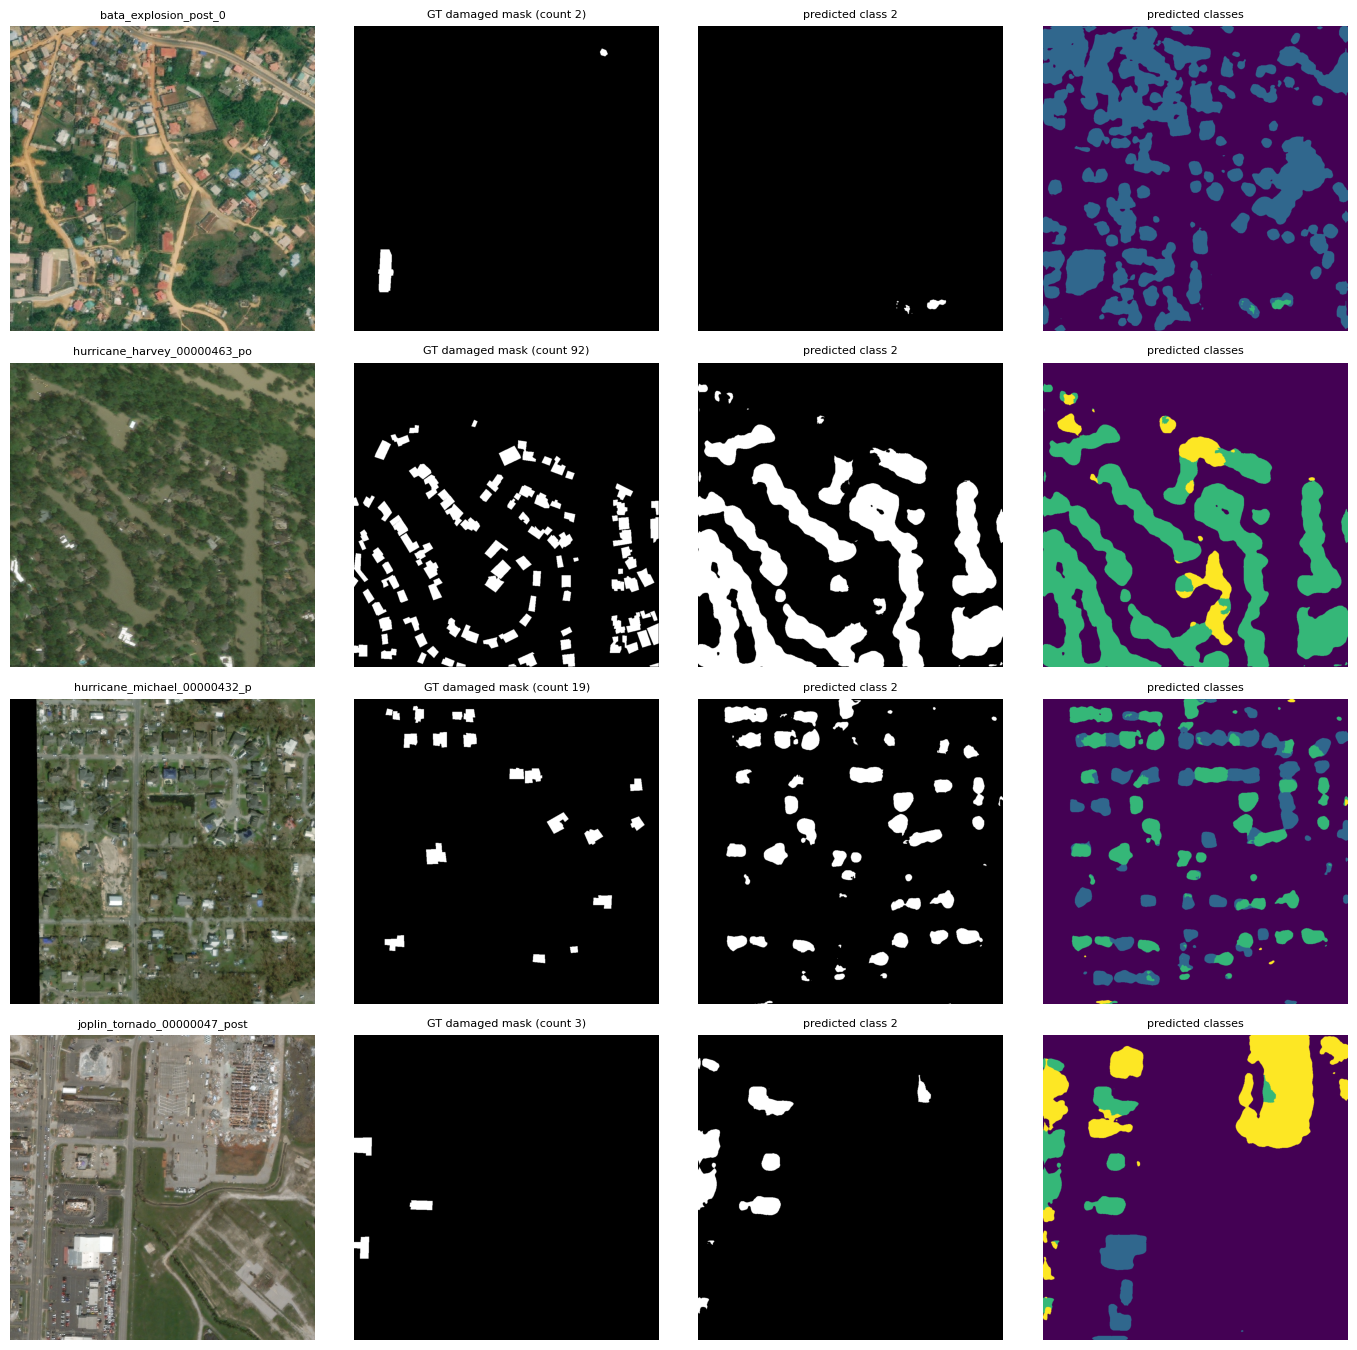

In [6]:
# ── CELL 4b (diagnostic, run once): why is the U-Net IoU low? ──────────────────
import matplotlib.pyplot as plt

def _iou(a, b):
    u = (a | b).sum()
    return float((a & b).sum() / u) if u else float('nan')

def unet_diagnose(n=16, show=4):
    sub_ = M[::max(1, len(M) // n)][:n]
    agg = collections.defaultdict(list)
    gt_frac, pr_frac = collections.defaultdict(list), collections.defaultdict(list)
    shape_mismatch, cls_share, shown = 0, np.zeros(4), []
    for e in sub_:
        cls = _classmap_cached(e['image_path'])
        gm = read_mask(e['mask_path'])
        if gm.shape != cls.shape:
            shape_mismatch += 1
            gm = cv2.resize(gm, (cls.shape[1], cls.shape[0]), interpolation=cv2.INTER_NEAREST)
        gb = gm > 127
        kind = 'destroyed' if e['cls_description'] == CLS_DESTROYED else 'damaged'
        target = 3 if kind == 'destroyed' else 2
        agg[f'{kind}: matching class ({target})'].append(_iou(gb, cls == target))
        agg[f'{kind}: classes 2|3'].append(_iou(gb, (cls == 2) | (cls == 3)))
        agg[f'{kind}: all buildings'].append(_iou(gb, cls >= 1))
        gt_frac[kind].append(gb.mean()); pr_frac[kind].append((cls == target).mean())
        cls_share += np.bincount(cls.ravel(), minlength=4)[:4] / cls.size
        if len(shown) < show: shown.append((e, cls, gb, kind, target))
    print(f'── U-Net diagnosis on {len(sub_)} entries ──')
    print(f'   mask/image shape mismatches (resized with nearest): {shape_mismatch}')
    for kind in gt_frac:
        print(f'   {kind}: GT mask covers {np.mean(gt_frac[kind]) * 100:.2f}% of pixels | predicted matching class covers {np.mean(pr_frac[kind]) * 100:.2f}%')
    print('   predicted class share  BG/Intact/Damaged/Destroyed: ' + ' / '.join(f'{v * 100:.1f}%' for v in cls_share / len(sub_)))
    print('   mean IoU of the GT mask vs each predicted variant:')
    for k, v in sorted(agg.items()):
        print(f'      {k:32s} {np.nanmean(v):.3f}')
    fig, axes = plt.subplots(len(shown), 4, figsize=(14, 3.4 * len(shown)))
    axes = np.atleast_2d(axes)
    for r, (e, cls, gb, kind, target) in enumerate(shown):
        img = cv2.cvtColor(cv2.imread(e['image_path']), cv2.COLOR_BGR2RGB)
        axes[r, 0].imshow(img); axes[r, 0].set_title(stem(e['post_image_path'])[:28], fontsize=8)
        axes[r, 1].imshow(gb, cmap='gray'); axes[r, 1].set_title(f'GT {kind} mask (count {e["oracle_count"]})', fontsize=8)
        axes[r, 2].imshow(cls == target, cmap='gray'); axes[r, 2].set_title(f'predicted class {target}', fontsize=8)
        axes[r, 3].imshow(cls, cmap='viridis', vmin=0, vmax=3); axes[r, 3].set_title('predicted classes', fontsize=8)
        for a_ in axes[r]: a_.axis('off')
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/unet_diagnosis.png', dpi=110)
    plt.show()

unet_diagnose()

In [7]:
# ── CELL 4c: when continuing an earlier run (RESUME_DIR set), redo ONLY the destroyed questions ──
# The earlier oracle runs gave destroyed questions the DAMAGED-mask count. Damaged rows are still valid and are kept.
if RESUME_DIR:
    for nm in ('ft_oracle_text', 'ft_oracle_image', 'base_oracle_image'):
        p = f'{OUT_DIR}/bdc_{nm}{TAG}.csv'
        if not os.path.exists(p): continue
        rows = list(csv.DictReader(open(p)))
        keep = [r for r in rows if r['cls'] != CLS_DESTROYED]
        with open(p, 'w', newline='') as f:
            w = csv.DictWriter(f, fieldnames=FIELDS); w.writeheader(); w.writerows(keep)
        print(f'{nm}: kept {len(keep)} damaged rows; {len(rows) - len(keep)} destroyed rows will be re-run with the destroyed mask')
else:
    print('RESUME_DIR not set → fresh run, nothing to trim.')

ft_oracle_text: kept 972 damaged rows; 683 destroyed rows will be re-run with the destroyed mask
ft_oracle_image: kept 972 damaged rows; 683 destroyed rows will be re-run with the destroyed mask
base_oracle_image: kept 294 damaged rows; 206 destroyed rows will be re-run with the destroyed mask


In [8]:
# ── CELL 5: Run all experiments (resumable, most important first) ──────────────
def sub(lst):
    if not SMOKE_TEST: return lst
    return lst[::max(1, len(lst) // SMOKE_N)][:SMOKE_N]

SUBSETS = {'M': sub(M), 'IMG': sub(WITH_IMG), 'MB': sub(MB)}

# (model, name, subset, use_image, count_source) — ordered by importance in case time runs out
EXPERIMENTS = [
    ('ft',   'image_only',                 'IMG', True,  None),       # true baseline
    ('ft',   'oracle_image',               'M',   True,  'oracle'),   # upper bound with image
    ('ft',   f'unet-{UNET_LABEL}_image',   'IMG', True,  'unet'),     # real hybrid
    ('ft',   'text_only',                  'M',   False, None),
    ('ft',   'oracle_text',                'M',   False, 'oracle'),
    ('base', 'image_only',                 'MB',  True,  None),
    ('base', 'oracle_image',               'MB',  True,  'oracle'),
]
if not UNET_PREDICT_MASK:
    EXPERIMENTS = [x for x in EXPERIMENTS if x[4] != 'unet']
if not RUN_BASE_MODEL:
    EXPERIMENTS = [x for x in EXPERIMENTS if x[0] != 'base']

stopped = False
for tag, model_id in (('ft', FT_MODEL), ('base', BASE_MODEL)):
    exps = [x for x in EXPERIMENTS if x[0] == tag]
    if not exps or stopped: continue
    vlm, proc = load_vlm(model_id)
    for (_, name, subset, use_img, csrc) in exps:
        if not run_experiment(vlm, proc, tag, name, SUBSETS[subset], use_img, csrc):
            stopped = True
            break
    del vlm, proc
    gc.collect(); torch.cuda.empty_cache()

print('\n⏱ Stopped early on the time budget — see Cell 6 for what finished.' if stopped
      else '\n✓ All experiments finished — run Cell 6 for the summary table.')

preprocessor_config.json:   0%|          | 0.00/575 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.78k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

✓ Qwen/Qwen2.5-VL-7B-Instruct loaded | free VRAM: 12.5 GB

▶ base/image_only: 500 entries (500 already done, 344 to run)


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


   first entry: 704 input tokens | image tensors passed to model: True
   [525/500] acc 31.6% | 2.3s/entry | ETA 12 min
   [550/500] acc 31.6% | 2.2s/entry | ETA 11 min
   [575/500] acc 31.3% | 2.2s/entry | ETA 10 min
   [600/500] acc 30.8% | 2.2s/entry | ETA 9 min
   [625/500] acc 31.2% | 2.2s/entry | ETA 8 min
   [650/500] acc 31.4% | 2.2s/entry | ETA 7 min
   [675/500] acc 31.7% | 2.2s/entry | ETA 6 min
   [700/500] acc 32.1% | 2.2s/entry | ETA 5 min
   [725/500] acc 32.4% | 2.2s/entry | ETA 4 min
   [750/500] acc 32.3% | 2.2s/entry | ETA 3 min
   [775/500] acc 32.3% | 2.2s/entry | ETA 3 min
   [800/500] acc 32.4% | 2.2s/entry | ETA 2 min
   [825/500] acc 32.7% | 2.2s/entry | ETA 1 min
✓ base/image_only: 278/844 = 32.94%  → /kaggle/working/bdc_base_image_only.csv

▶ base/oracle_image: 500 entries (294 already done, 413 to run)
   first entry: 1066 input tokens | image tensors passed to model: True
   [319/500] acc 83.4% | 2.2s/entry | ETA 14 min
   [344/500] acc 82.8% | 2.2s/entry |

In [9]:
# ── CELL 6: Summary table (accuracy, 95% CI, same-subset comparison) ───────────
def wilson(k, n, z=1.96):
    if n == 0: return 0.0, 0.0
    p = k / n
    d = 1 + z * z / n
    c = p + z * z / (2 * n)
    a = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - a) / d, (c + a) / d

CLS_D, CLS_T = 'Damaged building counting.', 'Totally-destroyed building counting.'
M_UIDS = {e['uid'] for e in M}
MB_UIDS = {e['uid'] for e in MB}

def stats(rows):
    n = len(rows); k = sum(r['correct'] == 'True' for r in rows)
    return n, k, (k / n * 100 if n else float('nan'))

files = sorted(glob.glob(f'{OUT_DIR}/bdc_*{TAG}.csv'))
files = [p for p in files if 'summary' not in p and (TAG or not p.endswith('_smoke.csv'))]

table = []
for p in files:
    base = os.path.basename(p)[4:-4]
    if TAG: base = base[:-len(TAG)]
    model, name = base.split('_', 1)
    if model not in ('ft', 'base'): continue
    with open(p) as f: rows = list(csv.DictReader(f))
    n, k, a = stats(rows)
    lo, hi = wilson(k, n)
    nm, km, am = stats([r for r in rows if int(r['uid']) in M_UIDS])
    nb_, kb_, ab_ = stats([r for r in rows if int(r['uid']) in MB_UIDS])
    table.append({
        'model': model, 'experiment': name, 'n': n, 'correct': k, 'acc_%': round(a, 2),
        'ci95_%': f'{lo * 100:.1f}-{hi * 100:.1f}',
        'n_on_M': nm, 'acc_on_M_%': round(am, 2),
        'n_on_MB': nb_, 'acc_on_MB_%': round(ab_, 2),
        'damaged_%': round(stats([r for r in rows if r['cls'] == CLS_D])[2], 2),
        'destroyed_%': round(stats([r for r in rows if r['cls'] == CLS_T])[2], 2),
        'unparsed': sum(r['pred_option'] == '?' for r in rows),
    })

order = {'text_only': 0, 'image_only': 1, 'oracle_text': 2, 'oracle_image': 3, 'unet_image': 4}
table.sort(key=lambda r: (r['model'], order.get(r['experiment'], 4 if r['experiment'].startswith('unet') else 9), r['experiment']))

cols = list(table[0].keys()) if table else []
print('| ' + ' | '.join(cols) + ' |')
print('|' + '---|' * len(cols))
for r in table:
    print('| ' + ' | '.join(str(r[c]) for c in cols) + ' |')

if table:
    with open(f'{OUT_DIR}/bdc_summary{TAG}.csv', 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=cols); w.writeheader(); w.writerows(table)
    print(f'\n✓ Saved → {OUT_DIR}/bdc_summary{TAG}.csv')

for p in files:
    base = os.path.basename(p)[4:-4]
    with open(p) as f: rows = list(csv.DictReader(f))
    bad = [r for r in rows if r['pred_option'] == '?'][:3]
    if bad:
        print(f'\\nUnparsed responses in {base}:')
        for r in bad: print('   ', repr(r['response'][:150]))

print('\nHow to read this:')
print(' • Compare fine-tuned experiments on the SAME entries with acc_on_M_% (M = image AND mask).')
print(' • Compare fine-tuned vs BASE model with acc_on_MB_% (MB = the sample the base model was run on).')
print(' • Random chance with 5 options is 20%. 95% CI = Wilson interval; small n means a wide interval.')
print(' • unparsed > 0 means the model gave no A-E letter for some entries (counted as wrong).')
print(' • oracle_* rows are an upper bound (ground-truth masks); unet_image is the real hybrid.')

| model | experiment | n | correct | acc_% | ci95_% | n_on_M | acc_on_M_% | n_on_MB | acc_on_MB_% | damaged_% | destroyed_% | unparsed |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| base | image_only | 844 | 278 | 32.94 | 29.9-36.2 | 844 | 32.94 | 500 | 34.4 | 29.82 | 37.32 | 36 |
| base | oracle_image | 707 | 617 | 87.27 | 84.6-89.5 | 707 | 87.27 | 500 | 89.4 | 83.77 | 95.33 | 0 |
| ft | text_only | 1701 | 359 | 21.11 | 19.2-23.1 | 1701 | 21.11 | 500 | 21.0 | 23.25 | 18.24 | 0 |
| ft | image_only | 1703 | 267 | 15.68 | 14.0-17.5 | 1701 | 15.7 | 500 | 18.2 | 15.09 | 16.46 | 189 |
| ft | oracle_text | 1701 | 1577 | 92.71 | 91.4-93.9 | 1701 | 92.71 | 500 | 93.2 | 89.92 | 96.43 | 0 |
| ft | oracle_image | 1701 | 1641 | 96.47 | 95.5-97.2 | 1701 | 96.47 | 500 | 97.2 | 96.19 | 96.84 | 0 |
| ft | unet-B1_image | 1703 | 394 | 23.14 | 21.2-25.2 | 1701 | 23.16 | 500 | 21.4 | 22.69 | 23.73 | 1 |
| ft | unet-B1cls_image | 1703 | 408 | 23.96 | 22.0-26.0 | 1701 | 23.93 | 500 | 23.0 | 23.4